<a href="https://colab.research.google.com/github/KP-365/hybrid-ope-lending/blob/main/cutoff_check_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Steps 1 to 3: cutoff check, Model 1 check, DM / IPS / DR and weight diagnostics

**Policy:** approve if the banded `risk_score >= c`. **Reward:** 1 if the loan is repaid, 0 if it defaults, and 0 for a rejected applicant. **Policy value V:** expected reward per scored applicant. We also report V divided by the approval rate, which is the repayment rate among approved applicants.

**Population:** scored applicants in the OPE period (2007 to 2014). Rejected applicants contribute 0 to IPS, so only logged-accepted loans with outcomes carry weight (w = 1 / p, where p is Model 1's acceptance probability).


## 0. Settings and imports

In [1]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

SAMPLE = 1.0                      # 0.05 for a smoke run
CUTOFFS = [700, 680, 660, 650, 640, 630, 620]
CAPS = [None, 100, 50, 20, 10]    # None = no cap
P_FLOOR = 1e-6                    # stops a propensity of exactly 0 giving an infinite weight
X_features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state']
cat_cols = ['purpose', 'zip3', 'state']

## 1. Load the data and Model 1

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/hybrid-ope-lending'
except ImportError:
    DATA_DIR = os.environ.get('LOCAL_DATA_DIR', '.')

combined = pd.read_parquet(f'{DATA_DIR}/lending_club_combined.parquet')
outcome_df = pd.read_parquet(f'{DATA_DIR}/lending_club_outcome.parquet')

# Model 1 (propensity). enable_categorical must be True or XGBoost refuses category columns.
m1 = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
m1.load_model(f'{DATA_DIR}/propensity_model.json')
m1_feat = m1.get_booster().feature_names
print('Model 1 expects, in this order:', m1_feat)
print('missing from combined:', [c for c in m1_feat if c not in combined.columns])
print('missing from outcome :', [c for c in m1_feat if c not in outcome_df.columns])

Mounted at /content/drive
Model 1 expects, in this order: ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state', 'year', 'month']
missing from combined: []
missing from outcome : []


## 2. Prepare both datasets

Same preparation as the earlier models: scored rows only, `risk_score` banded to multiples of 5 (removes the FICO midpoint fingerprint), OPE period only. Category columns in the outcome data are converted to the **same category codes as the combined data**, otherwise XGBoost would silently read different codes for the same purpose or state.

In [3]:
comb = combined[combined['risk_score'].notna()].copy()
comb['risk_score'] = comb['risk_score'] // 5 * 5
comb = comb[comb['in_ope_period'] == 1]

out = outcome_df[outcome_df['risk_score'].notna()].copy()
out['risk_score'] = out['risk_score'] // 5 * 5
out = out[out['year'] <= 2014]

for c in cat_cols:                       # one shared set of category codes
    out[c] = out[c].astype(comb[c].dtype)

if SAMPLE < 1.0:                         # same fraction in both so the weights stay consistent
    comb = comb.sample(frac=SAMPLE, random_state=0)
    out = out.sample(frac=SAMPLE, random_state=0)

N = len(comb)                            # scored applicants in the OPE period
print('applicants N:', N, ' accepted loans with outcomes:', len(out))
print('overall acceptance rate in comb:', comb['accepted'].mean().round(4))
print('default rate in out:', out['default'].mean().round(4))

applicants N: 3521146  accepted loans with outcomes: 358894
overall acceptance rate in comb: 0.1324
default rate in out: 0.1387


## 3. Step 1a: where is LendingClub's cutoff on these exact rows?

Acceptance rate by banded score. The cutoff is the lowest score where the rate stays above a threshold. It should still be about 660 on the OPE rows.

lowest score with acceptance >= 1%: 660.0
lowest score with acceptance >= 2%: 660.0
lowest score with acceptance >= 5%: 660.0
lowest score with acceptance >= 10%: 660.0


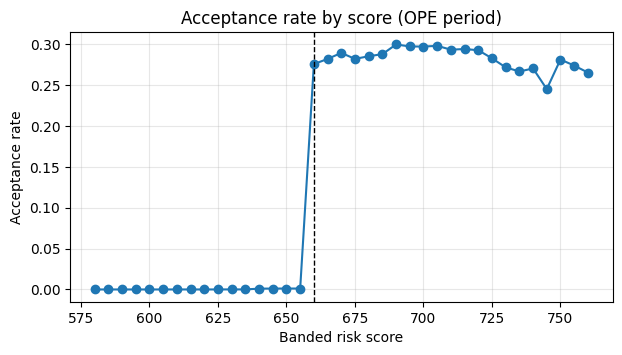

In [4]:
rate = comb.groupby('risk_score')['accepted'].agg(['mean', 'size'])
for thr in [0.01, 0.02, 0.05, 0.10]:
    ok = rate[(rate['mean'] >= thr) & (rate['size'] >= 100)]
    print(f'lowest score with acceptance >= {thr:.0%}:', ok.index.min())

r = rate[(rate.index >= 580) & (rate.index <= 760)]
plt.figure(figsize=(7, 3.5))
plt.plot(r.index, r['mean'], marker='o')
plt.axvline(660, color='k', ls='--', lw=1)
plt.xlabel('Banded risk score'); plt.ylabel('Acceptance rate'); plt.grid(alpha=0.3)
plt.title('Acceptance rate by score (OPE period)'); plt.show()

## 4. Step 1b: does Model 1 work on these rows?

If Model 1 is being fed correctly, the mean predicted propensity is close to the actual acceptance rate and the log loss is near 0.18 (these rows were in its training data, so it may look slightly better). A log loss near 0.37 to 0.40 means it is effectively predicting the average, which means the inputs do not line up.

In [5]:
p_chk = m1.predict_proba(comb[m1_feat])[:, 1]
print('mean predicted propensity:', p_chk.mean().round(4))
print('actual acceptance rate   :', comb['accepted'].mean().round(4))
ll = log_loss(comb['accepted'], p_chk, labels=[0, 1])
base_ll = log_loss(comb['accepted'], np.full(len(comb), comb['accepted'].mean()), labels=[0, 1])
print('Model 1 log loss:', round(ll, 4), '  constant baseline:', round(base_ll, 4))
assert ll < base_ll * 0.8, 'Model 1 is not beating the baseline by much: check feature names, order and category codes before going on'

mean predicted propensity: 0.1332
actual acceptance rate   : 0.1324
Model 1 log loss: 0.1718   constant baseline: 0.391


## 5. Outcome model (DM and the DR correction need it)

XGBoost with the Model 2 settings, trained on accepted loans from 2007 to 2013, so 2014 loans are out of sample. `year` is a feature. No cross-fitting (a stated limitation).

In [6]:
out_feat = X_features + ['year']
train = out[out['year'] <= 2013]
test = out[out['year'] == 2014]

om = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                       max_depth=3, learning_rate=0.05, min_child_weight=50)
om.fit(train[out_feat], train['default'])

if len(test) > 0:
    pt = om.predict_proba(test[out_feat])[:, 1]
    print('outcome model log loss on 2014:', round(log_loss(test['default'], pt, labels=[0, 1]), 4),
          ' baseline:', round(log_loss(test['default'], np.full(len(test), train['default'].mean()), labels=[0, 1]), 4))

# repayment probability m(x) = 1 - P(default) for every applicant and every accepted loan
m_comb = 1 - om.predict_proba(comb[out_feat])[:, 1]
m_out = 1 - om.predict_proba(out[out_feat])[:, 1]

outcome model log loss on 2014: 0.3907  baseline: 0.4


## 6. Propensities for the accepted loans

p is Model 1's probability that the applicant was accepted. The weight for an accepted loan is `approve(x) / p`.

In [7]:
p_out = np.clip(m1.predict_proba(out[m1_feat])[:, 1], P_FLOOR, 1.0)
r_out = 1 - out['default'].to_numpy()          # 1 = repaid
print('propensity of accepted loans: min', p_out.min(), ' median', np.median(p_out).round(4))
print('accepted loans with p < 0.01:', int((p_out < 0.01).sum()), ' with p < 0.001:', int((p_out < 0.001).sum()))

propensity of accepted loans: min 0.000961647  median 0.5739
accepted loans with p < 0.01: 45  with p < 0.001: 1


## 7. DM, IPS and DR for every cutoff, with a weight cap sweep

- **DM:** average of `approve(x) * m(x)` over all N applicants. Needs m(x) to be right for the rejected applicants the policy would approve, which is where it extrapolates.
- **IPS:** sum over accepted loans of `min(w, cap) * r`, divided by N.
- **DR:** DM plus the weighted correction `min(w, cap) * (r - m)`, divided by N.
- **Naive observed:** repayment rate among accepted loans with score >= c. This is what LendingClub actually saw. It is a reference, **not the truth**, because LendingClub rejected about 20% of applicants above 660, so no policy has a known true value on real data.

In [8]:
rows = []
for c in CUTOFFS:
    pi_comb = (comb['risk_score'] >= c).to_numpy()
    pi_out = (out['risk_score'] >= c).to_numpy()
    approve_rate = pi_comb.mean()
    dm = (pi_comb * m_comb).mean()
    w = pi_out / p_out
    naive = r_out[pi_out].mean() if pi_out.sum() > 0 else np.nan
    for cap in CAPS:
        wc = w if cap is None else np.minimum(w, cap)
        ips = (wc * r_out).sum() / N
        dr = dm + (wc * (r_out - m_out)).sum() / N
        wp = wc[pi_out]
        ess = (wp.sum() ** 2) / (wp ** 2).sum() if len(wp) else np.nan
        top = np.sort(wp)[::-1][:max(1, int(0.01 * len(wp)))].sum() / wp.sum() if len(wp) else np.nan
        rows.append({'cutoff': c, 'cap': 'none' if cap is None else cap,
                     'approve_rate': approve_rate,
                     'DM': dm / approve_rate, 'IPS': ips / approve_rate, 'DR': dr / approve_rate,
                     'naive_observed': naive,
                     'n_accepted_approved': int(pi_out.sum()), 'ESS': ess,
                     'max_weight': float(wp.max()) if len(wp) else np.nan,
                     'top1pct_weight_share': top})
res = pd.DataFrame(rows)
res.to_csv(f'{DATA_DIR}/results_steps_1_3.csv', index=False)
print('All estimates below are repayment rate among approved applicants.')
print(res.round(4).to_string(index=False))

All estimates below are repayment rate among approved applicants.
 cutoff  cap  approve_rate     DM    IPS     DR  naive_observed  n_accepted_approved           ESS  max_weight  top1pct_weight_share
    700 none        0.1856 0.8922 0.4805 0.8922          0.9021               143431  55141.515625    279.8871                0.0922
    700  100        0.1856 0.8922 0.4798 0.8925          0.9021               143431  60250.628906    100.0000                0.0905
    700   50        0.1856 0.8922 0.4776 0.8925          0.9021               143431  67231.843750     50.0000                0.0861
    700   20        0.1856 0.8922 0.4700 0.8927          0.9021               143431  80516.820312     20.0000                0.0707
    700   10        0.1856 0.8922 0.4559 0.8930          0.9021               143431  94669.781250     10.0000                0.0431
    680 none        0.3130 0.8733 0.4669 0.8720          0.8812               242190 100054.179688    279.8871                0.0873
   

## 8. Plots

Left: estimates against cutoff with a weight cap of 50. Right: effective sample size against cutoff for each cap. Look for where IPS and DR drift away from DM and where the ESS collapses.

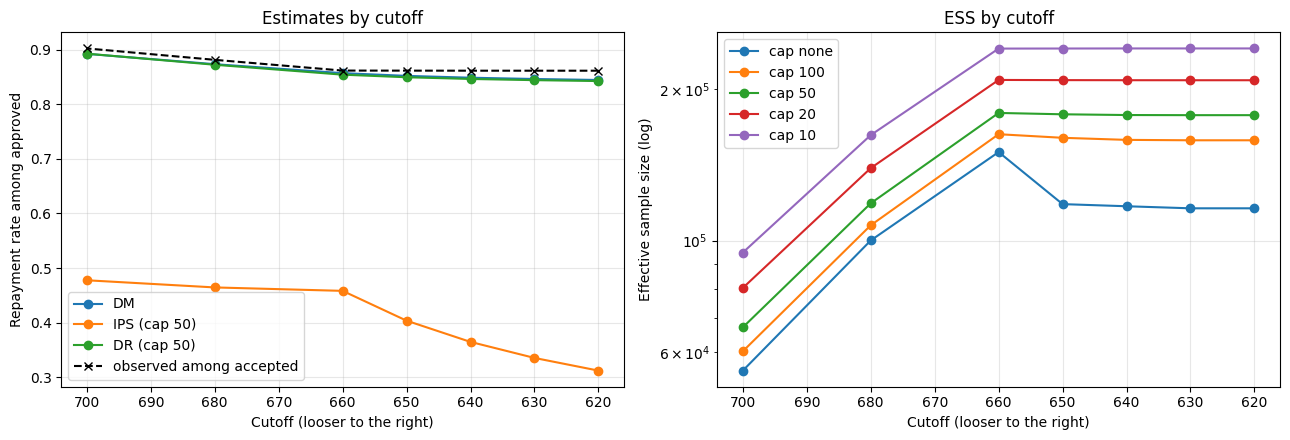

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
s = res[res['cap'] == 50].sort_values('cutoff')
a1.plot(s['cutoff'], s['DM'], marker='o', label='DM')
a1.plot(s['cutoff'], s['IPS'], marker='o', label='IPS (cap 50)')
a1.plot(s['cutoff'], s['DR'], marker='o', label='DR (cap 50)')
a1.plot(s['cutoff'], s['naive_observed'], 'k--', marker='x', label='observed among accepted')
a1.invert_xaxis(); a1.set_xlabel('Cutoff (looser to the right)'); a1.set_ylabel('Repayment rate among approved')
a1.set_title('Estimates by cutoff'); a1.legend(); a1.grid(alpha=0.3)
for cap, g in res.groupby('cap', sort=False):
    g = g.sort_values('cutoff')
    a2.plot(g['cutoff'], g['ESS'], marker='o', label=f'cap {cap}')
a2.invert_xaxis(); a2.set_yscale('log'); a2.set_xlabel('Cutoff (looser to the right)')
a2.set_ylabel('Effective sample size (log)'); a2.set_title('ESS by cutoff'); a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. How to read it

1. **Cutoff check (section 3):** about 660 means the policy family is anchored correctly.
2. **Model 1 check (section 4):** if the assert fails, stop and fix inputs before reading anything else.
3. **ESS and max weight (section 7):** as the cutoff loosens, ESS should fall and max weight rise. That is H3.
4. **DM against IPS and DR:** where they diverge, one of the models is wrong. DM does not use weights. IPS does not use the outcome model. DR uses both.
5. **Cap sweep:** the estimates should move as the cap tightens. How much they move is the bias you are buying to cut the variance.

## 10. Added after the first real run: why does IPS sit far below DM and DR?

Two things can pull IPS down. (a) Only about 77% of accepted loans have an outcome in the outcome file, so the weighted sum misses a quarter of the loans. (b) Model 1 was trained on these same rows, so its propensities for accepted loans can be too high, which makes the weights too small. This cell separates them. Weights summed over **all** accepted loans (outcome or not) should equal the number of applicants the policy approves, if p is calibrated. A ratio of 1.0 means yes.

In [10]:
acc = comb[comb['accepted'] == 1]
p_acc = np.clip(m1.predict_proba(acc[m1_feat])[:, 1], P_FLOOR, 1.0)
print('accepted loans in comb:', len(acc), ' loans with an outcome:', len(out), ' coverage:', round(len(out) / len(acc), 3))
print('acceptance rate among score >= 660:', round(comb.loc[comb['risk_score'] >= 660, 'accepted'].mean(), 4))
print('accepted loans with score < 660   :', int(((comb['accepted'] == 1) & (comb['risk_score'] < 660)).sum()))
chk = []
for c in [700, 680, 660]:
    pi_acc = (acc['risk_score'] >= c).to_numpy()
    n_appr = int((comb['risk_score'] >= c).sum())
    sw = (pi_acc / p_acc).sum()
    chk.append({'cutoff': c, 'sum_weights_all_accepted': round(sw), 'applicants_approved_by_policy': n_appr, 'ratio_should_be_1': round(sw / n_appr, 3)})
print(pd.DataFrame(chk).to_string(index=False))

accepted loans in comb: 466345  loans with an outcome: 358894  coverage: 0.77
acceptance rate among score >= 660: 0.2841
accepted loans with score < 660   : 489
 cutoff  sum_weights_all_accepted  applicants_approved_by_policy  ratio_should_be_1
    700                    447035                         653526              0.684
    680                    760124                        1102070              0.690
    660                   1141250                        1639964              0.696


## 11. Does the weight problem appear when the propensity model has not seen the loans?

Model 1 was trained on these rows, so it can look more confident than a model facing new loans. Here, a model trained on 2007 to 2013 only gives propensities for the 2014 accepted loans, and we compare the weights with Model 1's.

In [11]:
tr = comb[comb['year'] <= 2013]
m_oos = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
m_oos.fit(tr[m1_feat], tr['accepted'])

o14 = out[out['year'] == 2014]
r14 = []
for name, mdl in [('Model 1 (has seen these rows)', m1), ('trained on 2007 to 2013 only', m_oos)]:
    p = np.clip(mdl.predict_proba(o14[m1_feat])[:, 1], P_FLOOR, 1.0)
    for c in [680, 660]:
        pi = (o14['risk_score'] >= c).to_numpy()
        wp = (pi / p)[pi]
        r14.append({'propensity from': name, 'cutoff': c, 'n': int(pi.sum()),
                    'p<0.01': int((p[pi] < 0.01).sum()), 'p<0.001': int((p[pi] < 0.001).sum()),
                    'max_weight': round(float(wp.max()), 1), 'ESS': round(float(wp.sum() ** 2 / (wp ** 2).sum()))})
print(pd.DataFrame(r14).to_string(index=False))

              propensity from  cutoff      n  p<0.01  p<0.001  max_weight   ESS
Model 1 (has seen these rows)     680  99391      14        0       279.9 38367
Model 1 (has seen these rows)     660 162570      18        0       279.9 66164
 trained on 2007 to 2013 only     680  99391    1364     1288    329696.9   709
 trained on 2007 to 2013 only     660 162570    2255     2128    329696.9  1222


## 12. Self-normalised IPS and DR

Dividing by the sum of the weights instead of N cancels the missing-outcome problem and reports the repayment rate among approved applicants directly. Only cutoffs of 660 and above are shown: below 660 nobody was accepted, so every weight is zero and the answer would just repeat the 660 row.

In [12]:
rows = []
for c in [700, 680, 660]:
    pi_comb = (comb['risk_score'] >= c).to_numpy()
    pi_out = (out['risk_score'] >= c).to_numpy()
    dm_ratio = (pi_comb * m_comb).mean() / pi_comb.mean()
    w = pi_out / p_out
    for cap in [None, 50]:
        wc = w if cap is None else np.minimum(w, cap)
        rows.append({'cutoff': c, 'cap': 'none' if cap is None else cap, 'DM': dm_ratio,
                     'IPS_norm': (wc * r_out).sum() / wc.sum(),
                     'DR_norm': dm_ratio + (wc * (r_out - m_out)).sum() / wc.sum(),
                     'naive_observed': r_out[pi_out].mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 cutoff  cap     DM  IPS_norm  DR_norm  naive_observed
    700 none 0.8922    0.8940   0.8923          0.9021
    700   50 0.8922    0.8945   0.8928          0.9021
    680 none 0.8733    0.8741   0.8710          0.8812
    680   50 0.8733    0.8744   0.8713          0.8812
    660 none 0.8568    0.8551   0.8514          0.8616
    660   50 0.8568    0.8555   0.8517          0.8616
